<a href="https://colab.research.google.com/github/mayajdias/A04-clustering/blob/main/notebook_(6).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [ ]:
# Your Phase 1 solution to the problem goes here.


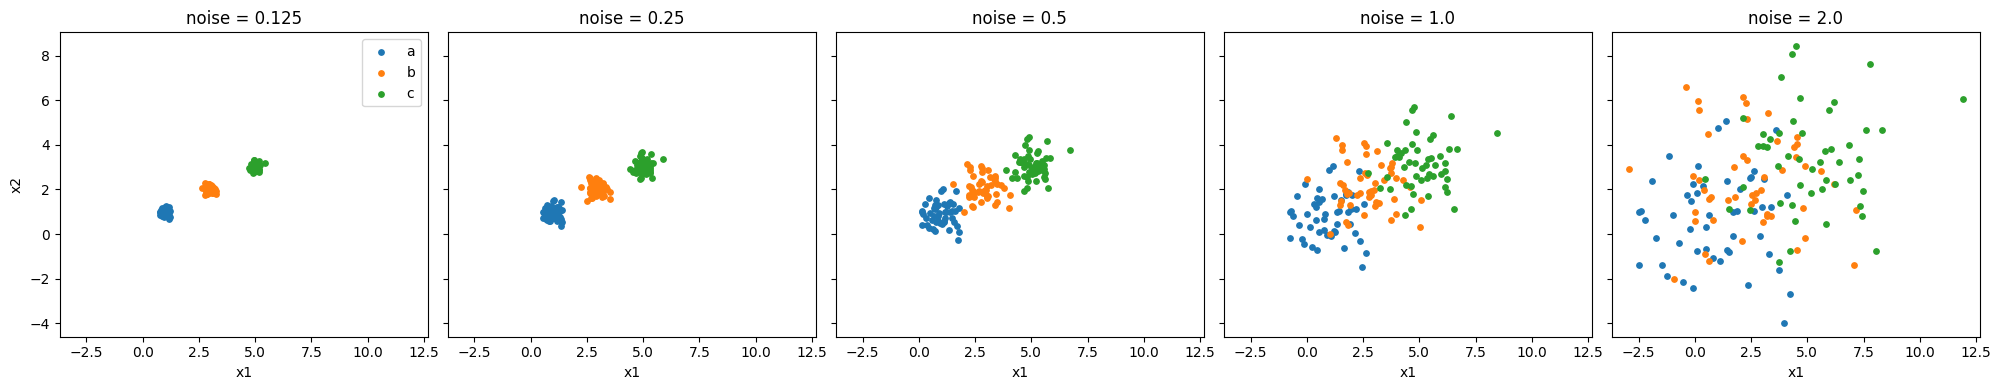

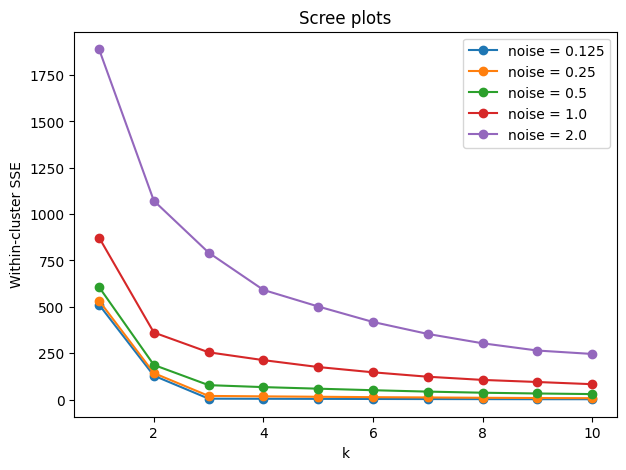

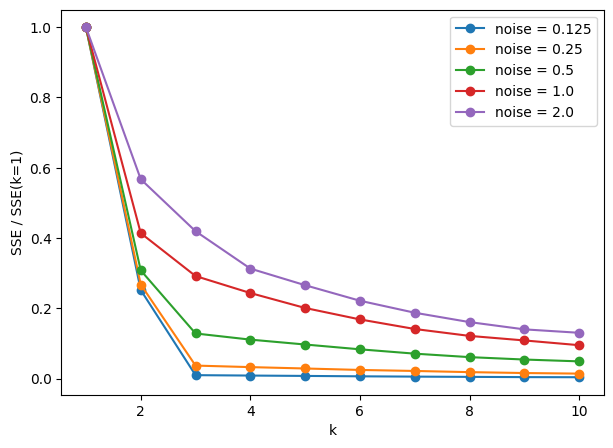

0.125 0.96 0.12
0.25 0.86 0.12
0.5 0.58 0.14
1.0 0.3 0.17
2.0 0.26 0.25


In [3]:
#Q1

#1
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


noises = [0.125, 0.25, 0.5, 1.0, 2.0]
dfs = {0.125: df0_125, 0.25: df0_25, 0.5: df0_5, 1.0: df1_0, 2.0: df2_0}

#2
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
for ax, n in zip(axes, noises):
    for g, sub in dfs[n].groupby('group'):
        ax.scatter(sub.x1, sub.x2, label=g, s=15)
    ax.set_title(f'noise = {n}')
    ax.set_xlabel('x1')
axes[0].set_ylabel('x2')
axes[0].legend()
plt.tight_layout()
plt.show()

#3
from sklearn.cluster import KMeans

ks = range(1, 11)
sse = {}
for n in noises:
    X = dfs[n][['x1', 'x2']]
    sse[n] = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]

# All five on one canvas, shared vertical axis
plt.figure(figsize=(7, 5))
for n in noises:
    plt.plot(ks, sse[n], marker='o', label=f'noise = {n}')
plt.xlabel('k')
plt.ylabel('Within-cluster SSE')
plt.title('Scree plots')
plt.legend()
plt.show()

# Optional: SSE relative to k = 1, so the elbows are comparable
plt.figure(figsize=(7, 5))
for n in noises:
    plt.plot(ks, np.array(sse[n]) / sse[n][0], marker='o', label=f'noise = {n}')
plt.xlabel('k')
plt.ylabel('SSE / SSE(k=1)')
plt.legend()
plt.show()

# Percent drop in SSE from k=2 to 3 and from k=3 to 4
for n in noises:
    s = sse[n]
    print(n, round(1 - s[2] / s[1], 2), round(1 - s[3] / s[2], 2))


Q1.4: SSE always decreases as k increases, so the useful question is what each extra cluster buys. In the low-noise data there are truly three groups. Going from 2 to 3 clusters splits a real group, which removes a large amount of variance. Going from 3 to 4 only cuts up a tight blob, which gains very little. The elbow is where improvement switches from capturing structure to fitting noise. As noise rises, the within-group spread approaches the distance between group centers, so the true 3-cluster solution is barely better than an arbitrary partition. The curve becomes smooth and the elbow disappears.

173 (148, 7)
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object
       Spending (2020 USD)  Spending per Capita  \
count           148.000000           148.000000   
mean          13153.747670           268.264494   
std           68005.236120           430.434878   
min               8.622460             0.580129   
25%             204.877177            20.553464   
50%             959.535443            81.506703   
75%            5289.998320           326.267753   
max          778397.200000          2520.398541   

       Percent of Government Spending  Percent of GDP  
count                      148.000000      148.000000  
mean                         0.061510        0.019619  
std                          0.046207        0.015033  
min                          0.004896        0.000054  
25%                          0.031352        0.010413  
50%      

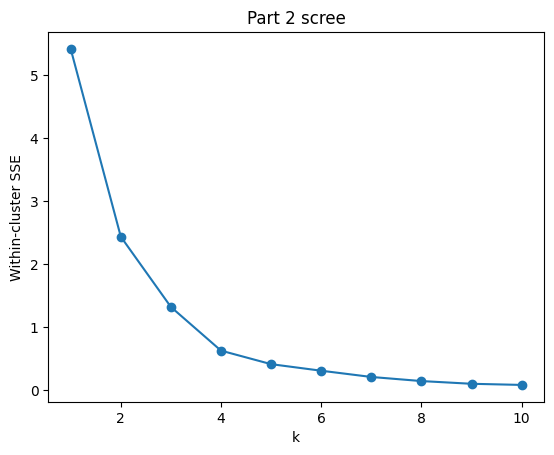

[0.55, 0.46, 0.52, 0.34, 0.25, 0.32, 0.31, 0.29, 0.17]


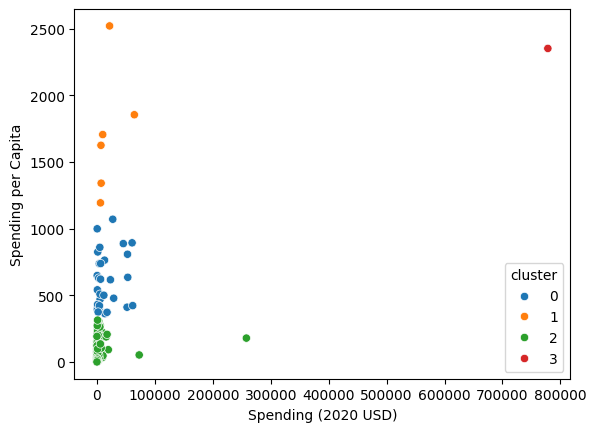

cluster                               0             1              2  \
Spending (2020 USD) count     30.000000      6.000000     111.000000   
                    mean   17077.591354  19443.362047    4859.185065   
                    std    20583.053357  22861.507114   25405.739131   
                    min      405.790494   6095.708713       8.622460   
                    25%     2294.039665   7023.251766     130.010211   
                    50%     5857.060906   8624.225729     382.464677   
                    75%    26296.001003  18857.070183    2297.032353   
                    max    61712.537169  64558.400000  257973.429834   
Spending per Capita count     30.000000      6.000000     111.000000   
                    mean     607.478618   1706.721916      80.061470   
                    std      206.928757    466.375705      83.501824   
                    min      362.467076   1193.598730       0.580129   
                    25%      422.208252   1412.083201      14.88

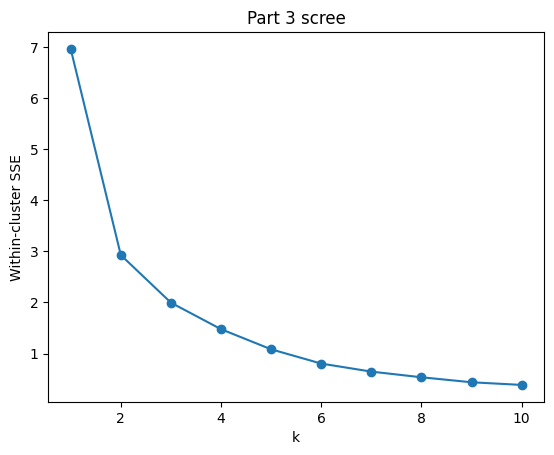

[0.58, 0.32, 0.26, 0.27, 0.26, 0.2, 0.17, 0.18, 0.12]


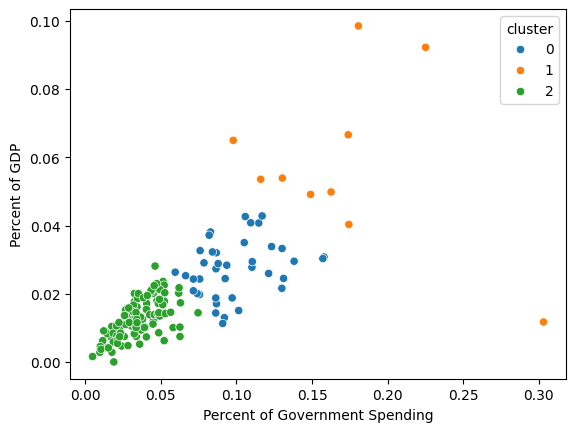

cluster                                       0          1          2
Percent of Government Spending count  39.000000  10.000000  99.000000
                               mean    0.098683   0.171289   0.035777
                               std     0.024125   0.058725   0.014549
                               min     0.059520   0.097882   0.004896
                               25%     0.082430   0.135010   0.025921
                               50%     0.092044   0.168248   0.034261
                               75%     0.112633   0.179081   0.047402
                               max     0.157918   0.303027   0.074624
Percent of GDP                 count  39.000000  10.000000  99.000000
                               mean    0.027412   0.058071   0.012664
                               std     0.008191   0.024867   0.005681
                               min     0.011317   0.011742   0.000054
                               25%     0.021254   0.049297   0.008393
                    

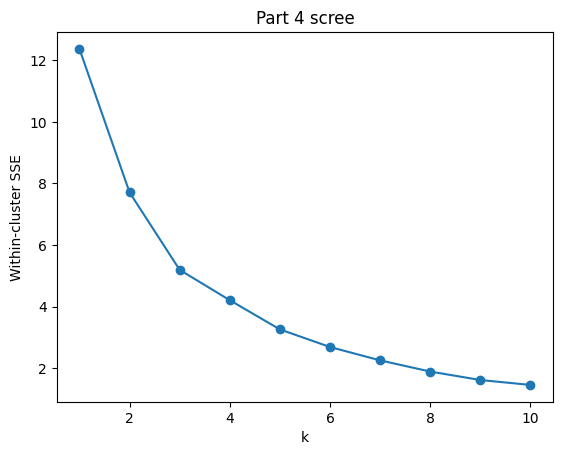

[0.38, 0.33, 0.19, 0.23, 0.18, 0.16, 0.16, 0.15, 0.1]


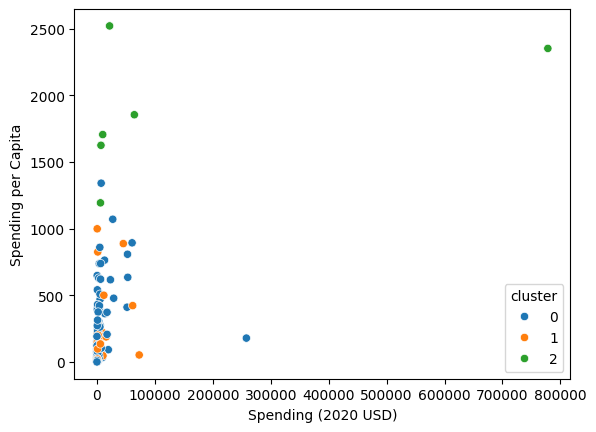

cluster                                           0             1  \
Spending (2020 USD)            count     111.000000     31.000000   
                               mean     7086.472777   8786.086602   
                               std     26479.379918  17901.909108   
                               min         8.622460    162.373364   
                               25%       130.010211    467.787851   
                               50%       567.650747   1404.787234   
                               75%      3910.107493   7739.166193   
                               max    257973.429834  72937.064048   
Spending per Capita            count     111.000000     31.000000   
                               mean      196.926833    212.689100   
                               std       267.788506    257.841988   
                               min         0.580129     18.297119   
                               25%        14.880549     46.485917   
                               50%

In [6]:
#Q2
#1
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

raw = pd.read_csv('SIPRI Military Expenditure Database.csv')
df = raw[raw['Year'] == 2020].dropna().reset_index(drop=True)
print(len(raw[raw['Year'] == 2020]), df.shape)   # 173 rows in 2020, 148 after dropna

num_cols = ['Spending (2020 USD)', 'Spending per Capita',
            'Percent of Government Spending', 'Percent of GDP']
print(df[num_cols].dtypes)
print(df[num_cols].describe())
print(df['Country'].duplicated().sum())          # 0 duplicates


#2
def minmax(s):
    return (s - s.min()) / (s.max() - s.min())

def scree(cols, title, kmax=10):
    X = df[cols].apply(minmax)
    sse = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_
           for k in range(1, kmax + 1)]
    plt.plot(range(1, kmax + 1), sse, marker='o')
    plt.xlabel('k'); plt.ylabel('Within-cluster SSE'); plt.title(title)
    plt.show()
    return sse

def cluster_and_plot(cols, k, xcol, ycol):
    X = df[cols].apply(minmax)
    out = df.copy()
    out['cluster'] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
    sns.scatterplot(data=out, x=xcol, y=ycol, hue='cluster', palette='tab10')
    plt.show()
    print(out.groupby('cluster')[cols].describe().T)
    print(out[out['Country'] == 'United States of America'][['Country', 'cluster']])
    return out

cols2 = ['Spending (2020 USD)', 'Spending per Capita']
sse2 = scree(cols2, 'Part 2 scree')
print([round(1 - sse2[i] / sse2[i-1], 2) for i in range(1, len(sse2))])
d2 = cluster_and_plot(cols2, k=4, xcol=cols2[0], ycol=cols2[1])

#3
cols3 = ['Percent of Government Spending', 'Percent of GDP']
sse3 = scree(cols3, 'Part 3 scree')
print([round(1 - sse3[i] / sse3[i-1], 2) for i in range(1, len(sse3))])
d3 = cluster_and_plot(cols3, k=3, xcol=cols3[0], ycol=cols3[1])


#4
sse4 = scree(num_cols, 'Part 4 scree')
print([round(1 - sse4[i] / sse4[i-1], 2) for i in range(1, len(sse4))])
d4 = cluster_and_plot(num_cols, k=3, xcol=cols2[0], ycol=cols2[1])

for name, d in [('Part 2', d2), ('Part 3', d3), ('Part 4', d4)]:
    print(name, d['cluster'].value_counts().sort_index().tolist())

yes, in a limited way. It separates three stories that raw rankings blur: size (the US, and other large spenders), wealth-driven intensity (per capita: Gulf states, Israel, Singapore), and burden (Part 3 clusters such as Belarus, Pakistan, Armenia). It also shows that the answer depends on which variables you choose. Limits:

The solution is sensitive to scaling: one extreme outlier (the US) dominates min-max scaling in Part 2.
Choosing k is a judgment call when the elbow is soft (Part 3).
The clusters describe similarity in these variables, not causes, and cluster numbers are arbitrary labels.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

### *AI-proposed changes


### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]